In [1]:
# ==========================================
# IMPORT REQUIRED LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Download NLTK stopwords (run once)
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [3]:
# ==========================================
# TASK 1: DOWNLOAD AND LOAD THE DATASET
# ==========================================
# Note: The dataset files are tab-separated (\t) and have no header row.
files = ['amazon_cells_labelled.txt', 'imdb_labelled.txt', 'yelp_labelled.txt']
dfs = []

for file in files:
    # quoting=3 ignores double quotes inside reviews so lines don't break
    temp_df = pd.read_csv(file, sep='\t', header=None, names=['sentence', 'label'], quoting=3)
    dfs.append(temp_df)

# Combine all three datasets into one DataFrame (Total = 3000 rows)
df = pd.concat(dfs, ignore_index=True)

print("--- TASK 1: DATASET LOADED ---")
print(f"Dataset Shape: {df.shape}")
print(df.head(), "\n")

--- TASK 1: DATASET LOADED ---
Dataset Shape: (3000, 2)
                                            sentence  label
0  So there is no way for me to plug it in here i...      0
1                        Good case, Excellent value.      1
2                             Great for the jawbone.      1
3  Tied to charger for conversations lasting more...      0
4                                  The mic is great.      1 



In [4]:
# ==========================================
# TASK 2: BASIC TEXT PREPROCESSING
# ==========================================
def clean_text(text):
    # 1. Convert text to lowercase
    text = str(text).lower()
    # 2. Remove unnecessary characters, numbers, and punctuation (keep only letters and spaces)
    text = re.sub(r'[^a-z\s]', '', text)
    # 3. Remove extra whitespace (leading, trailing, and multiple spaces)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Create the 'clean_text' column
df['clean_text'] = df['sentence'].apply(clean_text)

print("--- TASK 2: COMPARE ORIGINAL VS PREPROCESSED TEXT ---")
for i in range(5):
    print(f"Original : {df['sentence'].iloc[i]}")
    print(f"Cleaned  : {df['clean_text'].iloc[i]}")
    print("-" * 50)
print("\n")

--- TASK 2: COMPARE ORIGINAL VS PREPROCESSED TEXT ---
Original : So there is no way for me to plug it in here in the US unless I go by a converter.
Cleaned  : so there is no way for me to plug it in here in the us unless i go by a converter
--------------------------------------------------
Original : Good case, Excellent value.
Cleaned  : good case excellent value
--------------------------------------------------
Original : Great for the jawbone.
Cleaned  : great for the jawbone
--------------------------------------------------
Original : Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
Cleaned  : tied to charger for conversations lasting more than minutesmajor problems
--------------------------------------------------
Original : The mic is great.
Cleaned  : the mic is great
--------------------------------------------------




--- TASK 3: DATA EXPLORATION ---
Positive Review Examples:
  [+] good case excellent value
  [+] great for the jawbone
  [+] the mic is great

Negative Review Examples:
  [-] so there is no way for me to plug it in here in the us unless i go by a converter
  [-] tied to charger for conversations lasting more than minutesmajor problems
  [-] i have to jiggle the plug to get it to line up right to get decent volume

Top 10 Frequent Words in POSITIVE Reviews: [('great', 198), ('good', 176), ('film', 98), ('phone', 86), ('movie', 83), ('one', 76), ('best', 63), ('well', 61), ('food', 60), ('place', 58)]
Top 10 Frequent Words in NEGATIVE Reviews: [('bad', 96), ('movie', 94), ('phone', 76), ('dont', 70), ('one', 67), ('like', 67), ('food', 64), ('time', 61), ('would', 57), ('film', 57)]


/tmp/ipykernel_1237/4128564494.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Count', y='Word', data=pos_df, ax=axes[0], palette='Greens_r')
/tmp/ipykernel_1237/4128564494.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Count', y='Word', data=neg_df, ax=axes[1], palette='Reds_r')


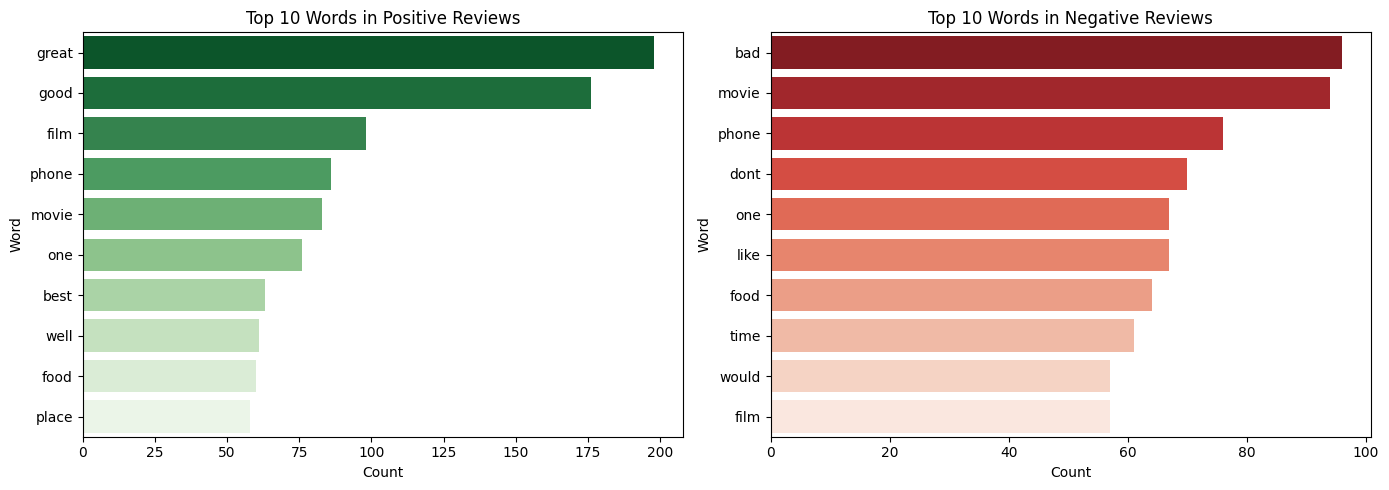

In [5]:
# ==========================================
# TASK 3: EXPLORE THE TEXT DATA
# ==========================================
print("--- TASK 3: DATA EXPLORATION ---")

# 1. Display Positive (1) and Negative (0) examples
print("Positive Review Examples:")
for text in df[df['label'] == 1]['clean_text'].head(3):
    print(f"  [+] {text}")

print("\nNegative Review Examples:")
for text in df[df['label'] == 0]['clean_text'].head(3):
    print(f"  [-] {text}")

# 2. Identify frequently occurring words (excluding stopwords for meaningful insights)
def get_top_words(text_series, n=10):
    all_words = " ".join(text_series).split()
    filtered_words = [word for word in all_words if word not in stop_words]
    return Counter(filtered_words).most_common(n)

top_pos_words = get_top_words(df[df['label'] == 1]['clean_text'], 10)
top_neg_words = get_top_words(df[df['label'] == 0]['clean_text'], 10)

print("\nTop 10 Frequent Words in POSITIVE Reviews:", top_pos_words)
print("Top 10 Frequent Words in NEGATIVE Reviews:", top_neg_words)

# 3. Visualize differences between Positive and Negative reviews
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Positive plot
pos_df = pd.DataFrame(top_pos_words, columns=['Word', 'Count'])
sns.barplot(x='Count', y='Word', data=pos_df, ax=axes[0], palette='Greens_r')
axes[0].set_title('Top 10 Words in Positive Reviews')

# Negative plot
neg_df = pd.DataFrame(top_neg_words, columns=['Word', 'Count'])
sns.barplot(x='Count', y='Word', data=neg_df, ax=axes[1], palette='Reds_r')
axes[1].set_title('Top 10 Words in Negative Reviews')

plt.tight_layout()
plt.show()

In [6]:
# ==========================================
# TASK 4: SPLIT THE DATASET
# ==========================================
X = df['clean_text']
y = df['label']

# 80% Training, 20% Testing (stratify ensures equal class balance in train and test sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("--- TASK 4: DATASET SPLIT ---")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples : {len(X_test)}\n")

--- TASK 4: DATASET SPLIT ---
Training samples: 2400
Testing samples : 600



In [7]:
# ==========================================
# TASK 5: CREATE BOW (AND TF-IDF) REPRESENTATION
# ==========================================
# Note: Your practical topic mentions TF-IDF, while Task 5 specifically asks for BOW.
# We create BOW as requested, and also TF-IDF for complete coverage.

# 5a. Bag of Words (BOW) Representation
bow_vectorizer = CountVectorizer(stop_words='english')
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

# 5b. TF-IDF Representation (Bonus for Topic alignment)
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("--- TASK 5: VECTORIZATION ---")
print(f"BOW Feature Matrix Shape   : {X_train_bow.shape}")
print(f"TF-IDF Feature Matrix Shape: {X_train_tfidf.shape}\n")

--- TASK 5: VECTORIZATION ---
BOW Feature Matrix Shape   : (2400, 4389)
TF-IDF Feature Matrix Shape: (2400, 4389)



In [8]:
# ==========================================
# TASK 6: TRAIN A MACHINE LEARNING MODEL
# ==========================================
# Using Logistic Regression (and SVM for comparison) on BOW features
model_lr = LogisticRegression(random_state=42)
model_lr.fit(X_train_bow, y_train)

model_svm = LinearSVC(random_state=42)
model_svm.fit(X_train_bow, y_train)

print("--- TASK 6: MODELS TRAINED SUCCESSFULLY ---\n")

--- TASK 6: MODELS TRAINED SUCCESSFULLY ---



--- TASK 7: MODEL EVALUATION (LOGISTIC REGRESSION + BOW) ---
Accuracy : 0.8117
Precision: 0.8086
Recall   : 0.8167
F1-Score : 0.8126

Detailed Classification Report:
              precision    recall  f1-score   support

Negative (0)       0.81      0.81      0.81       300
Positive (1)       0.81      0.82      0.81       300

    accuracy                           0.81       600
   macro avg       0.81      0.81      0.81       600
weighted avg       0.81      0.81      0.81       600



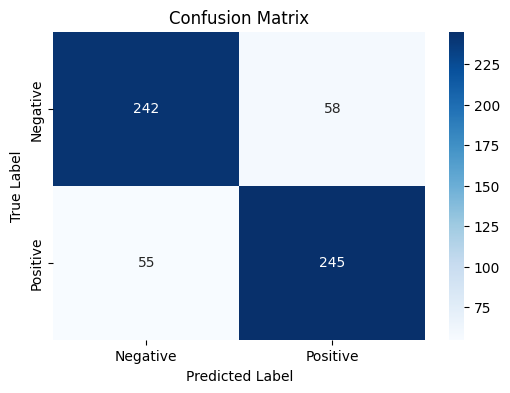

In [9]:
# ==========================================
# TASK 7: EVALUATE THE MODEL'S PERFORMANCE
# ==========================================
y_pred = model_lr.predict(X_test_bow)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("--- TASK 7: MODEL EVALUATION (LOGISTIC REGRESSION + BOW) ---")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}\n")

print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative (0)', 'Positive (1)']))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [10]:
# ==========================================
# TASK 8: TEST THE MODEL WITH NEW SENTENCES
# ==========================================
print("--- TASK 8: PREDICT ON NEW SENTENCES ---")

new_reviews = [
    "This phone battery lasts forever and the camera is amazing!",
    "Worst restaurant experience ever. The food was cold and tasteless.",
    "The movie was okay, a bit slow in the middle, not great.",
    "Absolutely loved the acting and the storyline!"
]

# Apply the exact same preprocessing and vectorization steps
cleaned_new_reviews = [clean_text(review) for review in new_reviews]
new_reviews_bow = bow_vectorizer.transform(cleaned_new_reviews)

predictions = model_lr.predict(new_reviews_bow)

for review, pred in zip(new_reviews, predictions):
    sentiment = "Positive (1)" if pred == 1 else "Negative (0)"
    print(f"Review    : '{review}'")
    print(f"Prediction: {sentiment}\n")

--- TASK 8: PREDICT ON NEW SENTENCES ---
Review    : 'This phone battery lasts forever and the camera is amazing!'
Prediction: Positive (1)

Review    : 'Worst restaurant experience ever. The food was cold and tasteless.'
Prediction: Negative (0)

Review    : 'The movie was okay, a bit slow in the middle, not great.'
Prediction: Positive (1)

Review    : 'Absolutely loved the acting and the storyline!'
Prediction: Positive (1)

